# Tutorial 2: Boundary conditions in 2D

Boundary conditions are **general**: each face of the box takes its own condition, Dirichlet,
Neumann or Robin, and its data and Robin coefficients can be arbitrary smooth functions along the
face. They are imposed through operations on the compressed operator, so changing a condition does
not change anything else in the problem setup.

We solve $-\Delta u = f$ on $[0,2]\times[0,1]$ with the manufactured solution
$u(x,y)=\sin(xy)+\cos(x+2y)$ and a different condition on each face:

| Face | Condition |
|---|---|
| $x=0$ | Dirichlet: $u=u^*(0,y)$ |
| $x=2$ | Robin with a variable coefficient: $\partial_x u + (1+y^2)\,u = g(y)$ |
| $y=0$ | Neumann: $-\partial_y u = g(x)$ (outward normal $-\mathbf e_y$) |
| $y=1$ | Dirichlet: $u=u^*(x,1)$ |

All data are loaded with **tensor cross-interpolation (TCI)**, which builds the QTT of a function
from a few samples, without forming the grid.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seemps.analysis.cross import BlackBoxLoadMPS, CrossStrategyDMRG, cross_interpolation
from seemps.analysis.mesh import ChebyshevInterval, Mesh, mps_to_mesh_matrix
from seemps.state import MPS

from seemps_galerkin import (
    BoundaryFace,
    BoundaryProblem,
    BulkProblem,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
    TensorField,
)
from seemps_galerkin.mps.factories import mps_identity
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform
from seemps_galerkin.solve import solve_mps_bvp


def u_exact(x, y):
    return np.sin(x * y) + np.cos(x + 2 * y)


def ux_exact(x, y):
    return y * np.cos(x * y) - np.sin(x + 2 * y)


def uy_exact(x, y):
    return x * np.cos(x * y) - 2 * np.sin(x + 2 * y)


def f_exact(x, y):
    return (x**2 + y**2) * np.sin(x * y) + 5 * np.cos(x + 2 * y)

## 1. Loading functions with TCI

`BlackBoxLoadMPS` wraps a function and a mesh; with `map_matrix=mps_to_mesh_matrix(sites)` and
binary physical dimensions it produces a QTT with the same site layout as the solver expects.
The function receives an array of shape `(d, number_of_points)`. `cross_interpolation` then samples
it adaptively until the requested tolerance is reached.

In [2]:
n = 5
N = 2**n
mesh = Mesh([ChebyshevInterval(0.0, 2.0, N, endpoints=False), ChebyshevInterval(0.0, 1.0, N, endpoints=False)])


def tci(func, mesh):
    sites = [int(np.log2(N)) for N in mesh.dimensions]
    black_box = BlackBoxLoadMPS(
        lambda points: func(*points),
        mesh,
        map_matrix=mps_to_mesh_matrix(sites),
        physical_dimensions=[2] * sum(sites),
    )
    return cross_interpolation(black_box, CrossStrategyDMRG(tol=1e-12)).mps


ψ_f = tci(f_exact, mesh)
print(f"source: {ψ_f.size} sites, bond dimension {ψ_f.max_bond_dimension()}")

source: 10 sites, bond dimension 15


## 2. Bulk problem

$C_{\alpha\beta}=\delta_{\alpha\beta}$ gives the Laplacian. Constant fields are multiples of
`mps_identity`, with one binary site per bit of every coordinate.

In [3]:
principal = TensorField[MPS]((2, 2, 1, 1), mesh.dimensions)
principal[0, 0, 0, 0] = mps_identity(2 * n)
principal[1, 1, 0, 0] = mps_identity(2 * n)
source = TensorField[MPS]((1,), mesh.dimensions)
source[0] = ψ_f
bulk = BulkProblem(mesh, principal, TensorField[MPS]((1, 1), mesh.dimensions), source)

## 3. Boundary conditions

Boundary data live on the face, that is, on the mesh with the normal coordinate removed. The face
$x=0$ has the mesh of $y$, and the face $y=0$ the mesh of $x$. Each face is identified by
`BoundaryFace(dim, is_left)`.

In [4]:
x_interval, y_interval = mesh.intervals
mesh_x, mesh_y = Mesh([x_interval]), Mesh([y_interval])
conditions = []

# x = 0: Dirichlet
data = TensorField[MPS]((1,), mesh_y.dimensions)
data[0] = tci(lambda y: u_exact(0.0, y), mesh_y)
conditions.append(DirichletBoundaryCondition(BoundaryFace(0, is_left=True), data))

# x = 2: Robin, ∂u/∂x + k(y) u = g(y)
k = lambda y: 1 + y**2
robin = TensorField[MPS]((1, 1), mesh_y.dimensions)
robin[0, 0] = tci(k, mesh_y)
data = TensorField[MPS]((1,), mesh_y.dimensions)
data[0] = tci(lambda y: ux_exact(2.0, y) + k(y) * u_exact(2.0, y), mesh_y)
conditions.append(RobinBoundaryCondition(BoundaryFace(0, is_left=False), robin, data))

# y = 0: Neumann, -∂u/∂y = g(x); a Robin condition with an empty reaction
data = TensorField[MPS]((1,), mesh_x.dimensions)
data[0] = tci(lambda x: -uy_exact(x, 0.0), mesh_x)
conditions.append(RobinBoundaryCondition(BoundaryFace(1, is_left=True), TensorField[MPS]((1, 1), mesh_x.dimensions), data))

# y = 1: Dirichlet
data = TensorField[MPS]((1,), mesh_x.dimensions)
data[0] = tci(lambda x: u_exact(x, 1.0), mesh_x)
conditions.append(DirichletBoundaryCondition(BoundaryFace(1, is_left=False), data))

boundary = BoundaryProblem(mesh, conditions)

## 4. Solve and check

The solution is a QTT of Chebyshev coefficients over both coordinates. On a small grid we can
expand it to compare with the exact solution; the nodal values are ordered as `(x, y)`. The error
is set by the default tolerance of the QTT solver, which Tutorial 3 shows how to change.

max error 5.1e-08, solution bond dimension 8


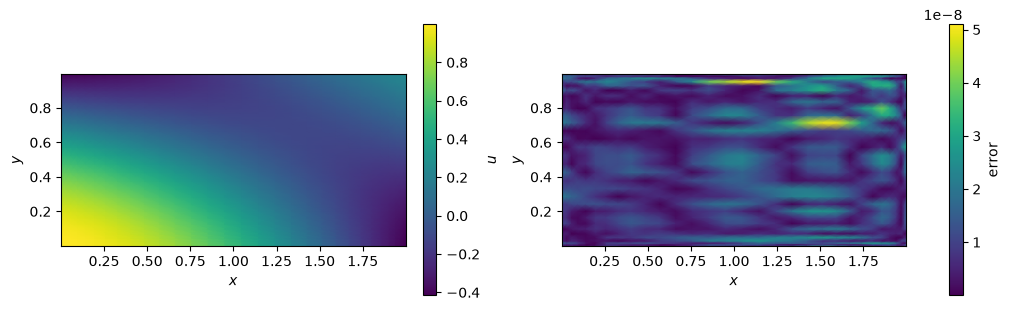

In [5]:
ψ = solve_mps_bvp(bulk, boundary)
u = mps_chebyshev_transform(ψ, [n, n], inverse=True).to_vector().reshape(N, N)

X, Y = np.meshgrid(x_interval.to_vector(), y_interval.to_vector(), indexing="ij")
error = np.max(np.abs(u - u_exact(X, Y)))
print(f"max error {error:.1e}, solution bond dimension {ψ.max_bond_dimension()}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
image = axs[0].pcolormesh(X, Y, u, shading="gouraud")
fig.colorbar(image, ax=axs[0], label="$u$")
image = axs[1].pcolormesh(X, Y, np.abs(u - u_exact(X, Y)), shading="gouraud")
fig.colorbar(image, ax=axs[1], label="error")
for ax in axs:
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
plt.show()

## 5. Changing conditions

Any face can be switched to another type without touching the rest of the setup. Here all four
faces become Dirichlet faces, with data again given by functions.

In [6]:
faces = [
    (BoundaryFace(0, True), mesh_y, lambda y: u_exact(0.0, y)),
    (BoundaryFace(0, False), mesh_y, lambda y: u_exact(2.0, y)),
    (BoundaryFace(1, True), mesh_x, lambda x: u_exact(x, 0.0)),
    (BoundaryFace(1, False), mesh_x, lambda x: u_exact(x, 1.0)),
]
conditions = []
for face, face_mesh, g in faces:
    data = TensorField[MPS]((1,), face_mesh.dimensions)
    data[0] = tci(g, face_mesh)
    conditions.append(DirichletBoundaryCondition(face, data))

ψ = solve_mps_bvp(bulk, BoundaryProblem(mesh, conditions))
u = mps_chebyshev_transform(ψ, [n, n], inverse=True).to_vector().reshape(N, N)
print(f"max error with four Dirichlet faces: {np.max(np.abs(u - u_exact(X, Y))):.1e}")

max error with four Dirichlet faces: 5.1e-08


## Summary

- Each face takes its own condition: `DirichletBoundaryCondition(face, data)` or
  `RobinBoundaryCondition(face, reaction, data)`; an empty reaction gives a Neumann condition.
- Robin conditions read $(C\nabla u)\cdot n + S u = g$ with the outward normal $n$.
- Data and Robin coefficients are arbitrary functions on the face mesh, loaded with TCI.